# Пример: dense GAN для генерации рукописных цифр

Этот ноутбук строит и обучает генеративно-состязательную сеть на
первых 10 000 изображений MNIST. Это полный пример, который нужно
выполнять сверху вниз до перехода к самостоятельному Fashion-MNIST
варианту.

## Как читать пример

GAN не получает метки цифр в качестве целевых значений. Цифры и их
метки нужны только для визуального знакомства с данными. На каждом
обучающем шаге есть две разные задачи: дискриминатор видит реальные и
синтетические изображения, а генератор получает случайный шум и
учится повышать оценку «настоящее» от фиксированного дискриминатора.

## История одного мини-пакета — без формул

Представьте две роли. **Генератор** — художник: ему дают карточку со
100 случайными числами, и он рисует одну картинку. **Дискриминатор** —
проверяющий: он видит картинку и отвечает одним числом, насколько она
похожа на настоящую. У проверяющего на столе лежит сразу пачка из
$B$ реальных цифр и $B$ только что нарисованных цифр. Это и есть
мини-пакет.

Сначала проверяющий получает обратную связь и меняет **только свои**
веса: настоящие цифры надо считать настоящими, рисунки художника —
синтетическими. Затем художник делает новую пачку рисунков и меняет
**только свои** веса: теперь его цель — заставить проверяющего считать
рисунки настоящими. В коде ниже эти два коротких разговора происходят
внутри одной функции `train_step`.

### Четыре слова, которые встретятся дальше

**Параметры** — числа внутри слоёв, которые сеть может менять.
**Прямой проход** — путь от входа к ответу: шум проходит через G, а
картинка — через D. **Потеря** — одно число, показывающее, насколько
ответ сейчас не соответствует цели. **Градиент** — подсказка к каждому
параметру: в какую сторону слегка сдвинуть его, чтобы потеря стала
меньше. `GradientTape` находит такие подсказки, а Adam делает шаг.

## Этап 1. Воспроизводимая конфигурация и соглашения о формах

**Зачем:** все параметры запуска находятся в одной ячейке. Размер
пакета обозначен $B$, размерность шума — 100, развёрнутого изображения
— 784. **Результат:** определены случайное начальное состояние,
каталоги артефактов и константы обучения. **Проверьте:** TensorFlow
сообщает версию, а устройство не выбирается вручную.

### Как читать форму

Запись `(B, 100)` означает прямоугольную таблицу: строка — один
объект, 100 столбцов — его случайные координаты. `(B, 784)` — такая
же пачка, но каждая строка содержит все пиксели цифры $28\times28$.
Число `B` меняется от пакета к пакету; 100 и 784 задают смысл одной
строки. Не нужно запоминать формы отдельно: прослеживайте путь
`шум (B,100) → G → изображение (B,784) → D → оценка (B,1)`.

In [1]:
from __future__ import annotations

# Path нужен только для воспроизводимого сохранения сеток; на граф
# производных GAN он не влияет.
from pathlib import Path

# NumPy работает с подготовленными массивами и историями, а TensorFlow
# — с тензорами, моделями и автоматическим дифференцированием.
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# Один seed синхронно фиксирует инициализацию весов и поток шума.
SEED = 42
DATASET_NAME = 'MNIST'
MAX_EXAMPLES = 10_000
IMAGE_HEIGHT = 28
IMAGE_WIDTH = 28
# Dense-сети не видят двумерную геометрию: 28×28 превращается в 784.
IMAGE_DIM = IMAGE_HEIGHT * IMAGE_WIDTH
NOISE_DIM = 100
BATCH_SIZE = 128
EPOCHS = 105
LEARNING_RATE = 2e-4
BETA_1 = 0.5
REAL_LABEL = 0.9
FAKE_LABEL = 0.0
GENERATOR_TARGET = 1.0
SAVE_EVERY = 20

# Keras использует собственные генераторы случайных чисел, поэтому
# фиксируем их до создания моделей и первого шума.
tf.keras.utils.set_random_seed(SEED)
artifact_dir = Path('artifacts/mnist_dense_gan')
artifact_dir.mkdir(parents=True, exist_ok=True)

print(f'TensorFlow: {tf.__version__}; данные: {DATASET_NAME}')
print(f'Формы: шум (B, {NOISE_DIM}), изображение (B, {IMAGE_DIM}), решение D (B, 1)')

I0000 00:00:1789715034.198900  243541 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789715034.199155  243541 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


TensorFlow: 2.21.0; данные: MNIST
Формы: шум (B, 100), изображение (B, 784), решение D (B, 1)


I0000 00:00:1789715034.754329  243541 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789715034.754496  243541 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


## Этап 2. Данные, нормализация и роль меток

**Вход:** массив изображений формы $(N,28,28)$ и массив классов
$(N)$. **Действие:** используются первые 10 000 изображений, значения
пикселей переводятся из $[0,255]$ в $[-1,1]$, затем каждое изображение
разворачивается в строку из 784 чисел. **Результат:** реальная выборка
формы $(N,784)$ и мини-пакеты $(B,784)$.

Метки классов не передаются ни в генератор, ни в дискриминатор. GAN
различает только происхождение изображения: настоящее или
синтетическое. Метки ниже служат исключительно подписями для проверки
корректности загрузки.

### Что именно меняет нормализация

Файл MNIST хранит яркость пикселя числом от 0 до 255. Последний слой
генератора — `tanh`, поэтому его рисунок естественно лежит между -1 и
1. Код переводит реальные пиксели в тот же диапазон. Это похоже на
договор о единицах измерения: без него проверяющий мог бы мгновенно
отличить источники по шкале чисел, а не по форме цифры.

После `reshape` цифра не становится «одномерной» по смыслу: 784 числа
всё ещё описывают те же 28 строк по 28 пикселей. Dense-слой просто
получает их как длинный список. `dataset` хранит только картинки;
`y_train` намеренно остаётся вне обучения.

E0000 00:00:1789715050.650979  243541 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: CUDA_ERROR_NO_DEVICE: no CUDA-capable device is detected


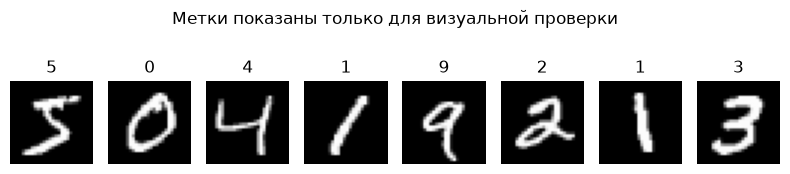

Первый мини-пакет: (128, 784)


In [2]:
# y_train сохраняется только для подписей. В GAN оно никогда не будет
# передано в loss: D учится отличать источник изображения, не цифру.
(x_train, y_train), _ = tf.keras.datasets.mnist.load_data()
x_train = x_train[:MAX_EXAMPLES].astype('float32')
y_train = y_train[:MAX_EXAMPLES]
# Выход tanh генератора лежит в [-1, 1]; реальные пиксели переводим
# в тот же диапазон, иначе D смог бы различать источники по масштабу.
x_train = (x_train - 127.5) / 127.5
x_train = x_train.reshape(-1, IMAGE_DIM)

assert x_train.shape == (MAX_EXAMPLES, IMAGE_DIM)
assert y_train.shape == (MAX_EXAMPLES,)
assert np.isfinite(x_train).all()
assert -1.0 <= float(x_train.min()) <= float(x_train.max()) <= 1.0

# Dataset содержит только x_train. shuffle меняет состав пакетов,
# batch создаёт тензор (B, 784), а prefetch готовит следующий пакет.
dataset = (
    tf.data.Dataset.from_tensor_slices(x_train)
    .shuffle(MAX_EXAMPLES, seed=SEED, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)
    .prefetch(tf.data.AUTOTUNE)
)

plt.figure(figsize=(8, 2))
for index in range(8):
    plt.subplot(1, 8, index + 1)
    plt.imshow(x_train[index].reshape(28, 28), cmap='gray')
    plt.title(str(int(y_train[index])))
    plt.axis('off')
plt.suptitle('Метки показаны только для визуальной проверки')
plt.tight_layout()
plt.show()
print('Первый мини-пакет:', tuple(next(iter(dataset)).shape))

## Этап 3. Генератор, дискриминатор и диагностический проход

**Генератор:** $100\to256\to512\to1024\to784$ с LeakyReLU и
завершающим tanh. **Дискриминатор:** $784\to1024\to512\to256\to1$ с
LeakyReLU, Dropout и sigmoid. Важна последняя активация: её выход —
вероятность, пригодная для бинарной кросс-энтропии.

**Проверка:** шум $(B,100)$ превращается в изображения $(B,784)$,
затем в оценки $(B,1)$. Диагностический проход не обновляет параметры.

### Что делают две сети

Генератор не выбирает готовую цифру из набора: в начале он превращает
шум почти в случайный рисунок. Его веса постепенно учатся связывать
похожие точки пространства шума с похожими штрихами. Дискриминатор
читает 784 яркости и возвращает одно число от 0 до 1. Близко к 1 —
«похоже на настоящее», близко к 0 — «похоже на рисунок генератора».

В этом dense-варианте сеть видит картинку как длинный список и не
знает заранее, что соседние числа — соседние пиксели. Это полезная
базовая линия: позднее свёрточная модель будет использовать геометрию
изображения явно.

In [3]:
# Независимая малая инициализация разрушает симметрию нейронов до
# первого шага: одинаковые веса иначе получали бы одинаковый градиент.
initializer = tf.keras.initializers.RandomNormal(stddev=0.02)


def make_generator() -> tf.keras.Model:
    # Ось B не задаётся в Input: Keras применяет одни веса к каждому
    # z_i формы (100,), возвращая пакет G(z) формы (B, 784).
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(NOISE_DIM,)),
            tf.keras.layers.Dense(256, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(512),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(1024),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dense(IMAGE_DIM, activation='tanh'),
        ],
        name='generator',
    )


def make_discriminator() -> tf.keras.Model:
    # Финальный sigmoid превращает скалярный логит в вероятность.
    # Именно поэтому BCE ниже создаётся с from_logits=False.
    return tf.keras.Sequential(
        [
            tf.keras.layers.Input(shape=(IMAGE_DIM,)),
            tf.keras.layers.Dense(1024, kernel_initializer=initializer),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(512),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(256),
            tf.keras.layers.LeakyReLU(negative_slope=0.2),
            tf.keras.layers.Dropout(0.3),
            tf.keras.layers.Dense(1, activation='sigmoid'),
        ],
        name='discriminator',
    )


# Этот проход строит веса и проверяет контракт форм, но не вызывает
# оптимизатор, поэтому параметры G и D ещё не изменяются.
generator = make_generator()
discriminator = make_discriminator()
diagnostic_noise = tf.random.normal((BATCH_SIZE, NOISE_DIM))
diagnostic_images = generator(diagnostic_noise, training=False)
diagnostic_scores = discriminator(diagnostic_images, training=False)

assert diagnostic_images.shape == (BATCH_SIZE, IMAGE_DIM)
assert diagnostic_scores.shape == (BATCH_SIZE, 1)
assert bool(tf.reduce_all(tf.math.is_finite(diagnostic_images)))
assert bool(tf.reduce_all((0.0 < diagnostic_scores) & (diagnostic_scores < 1.0)))
print('G(z):', diagnostic_images.shape, '; D(G(z)):', diagnostic_scores.shape)

G(z): (128, 784) ; D(G(z)): (128, 1)


## Этап 4. Попеременное состязательное обучение

В первой части «train_step» фиксируется генератор: его изображения
отделяются от графа, а градиенты применяются только к параметрам
дискриминатора. Настоящие изображения получают мягкую цель 0.9,
синтетические — 0.

Во второй части создаётся новый шум. Дискриминатор вычисляет ответ с
«training=False», но остаётся дифференцируемой функцией: градиент
проходит через его вычисление к $G$, а оптимизатор получает только
переменные генератора. Цель генератора равна 1, потому что он стремится
сделать синтетический образец неотличимым от настоящего.

### Два шага внутри `train_step`

**Шаг дискриминатора.** Код берёт `real_images` из `dataset`, создаёт
`discriminator_noise`, получает `fake_images` и вызывает
`tf.stop_gradient`. Эта операция оставляет изображение как есть, но
ставит воображаемую заглушку на стрелке обратно к генератору. Поэтому
`GradientTape` вычисляет, как изменить только проверяющего.

**Шаг генератора.** Создаётся *новый* `generator_noise`. Заглушки уже
нет: ошибка проходит от ответа дискриминатора через нарисованные
пиксели к весам генератора. `training=False` у дискриминатора означает
лишь «не использовать случайный Dropout в его ответе»; это не запрет
градиента. Параметры дискриминатора не меняются потому, что во второй
`apply_gradients` переданы только параметры генератора.

### Что такое BCE и мягкая метка

BCE — число, которое велико, когда уверенный ответ не совпадает с
целью. Для проверяющего цель настоящей цифры равна 0.9, а не 1.0:
небольшая осторожность часто мешает ему стать чрезмерно уверенным.
Для синтетической цифры цель 0. Для генератора та же синтетическая
цифра получает цель 1: художник пытается обмануть проверяющего.

В этом ноутбуке D уже возвращает вероятность $p\in(0,1)$ после
sigmoid. Для одной картинки и цели $y$ бинарная кросс-энтропия равна

$$
\operatorname{BCE}(y,p)=-y\log p-(1-y)\log(1-p).
$$

Если проверяющий уверенно говорит «0», когда цель близка к 1, первый
логарифм даёт большую ошибку. Если он уверен правильно, ошибка мала.
`BinaryCrossentropy(from_logits=False)` вычисляет эту величину для
всей пачки и усредняет её.

### Почему это правильная математика

У сетей есть два разных набора обучаемых чисел: $\theta_G$ — все веса
и смещения генератора, $\theta_D$ — все веса и смещения
дискриминатора. Функция потерь всегда заканчивается **одним числом**:
чем оно больше, тем сильнее текущий ответ расходится с целью. Частная
производная $\partial\mathcal L/\partial w$ говорит, как изменится
это число при очень малом изменении одного параметра $w$. Поэтому
общий принцип обучения записывают так:

$$
\theta \leftarrow \theta - \eta\,\nabla_\theta\mathcal L,
$$

где $\eta$ — маленький размер шага. Минус означает движение туда, где
ошибка уменьшается. На практике Adam выбирает размер корректировки
умнее простого постоянного $\eta$, но использует те же градиенты.

В фазе D код минимизирует

$$
\mathcal L_D=\tfrac12\bigl[
\operatorname{BCE}(0.9,D_{\theta_D}(\mathbf x_{\rm real}))+
\operatorname{BCE}(0,D_{\theta_D}(G_{\theta_G}(\mathbf z_D)))
\bigr]
$$

только по $\theta_D$. Во второй фазе минимизируется

$$
\mathcal L_G=\operatorname{BCE}
\bigl(1,D_{\theta_D}(G_{\theta_G}(\mathbf z_G))\bigr)
$$

только по $\theta_G$. Шум $\mathbf z$ не является весом и не
запоминается: он каждый раз лишь подаётся на вход общей функции
$G_{\theta_G}$. Обучение меняет правило преобразования шума, а не
отдельную случайную карточку.

Для генератора цепное правило читается справа налево:

$$
\frac{\partial\mathcal L_G}{\partial\theta_G}
=
\frac{\partial\mathcal L_G}{\partial D}
\frac{\partial D}{\partial G}
\frac{\partial G}{\partial\theta_G}.
$$

Дискриминатор здесь нужен как измерительный прибор: его операция
остаётся в цепочке и сообщает, какие пиксели повлияли на ошибку, хотя
его собственные параметры во второй фазе не обновляются.

### От математической формулы к TensorFlow: что делает каждый объект

Сначала отделите три очень разные сущности. `real_images`, шум и
изображения, созданные G, — **временные данные**: они нужны для
одного мини-пакета и не меняются оптимизатором. Веса и смещения слоёв
— объекты `tf.Variable`, то есть параметры $\theta_G$ и $\theta_D$:
именно их разрешено менять. `discriminator_loss` и `generator_loss` —
**скаляры**, по одному числу; они отвечают на вопрос «насколько плох
был этот ответ сети?» и становятся началом обратного прохода.

### Инфографика: две фазы одного пакета

![Два независимых обновления GAN: обучение дискриминатора, затем обучение генератора](assets/diagrams/gan_two_phase_training.svg)

На первой половине рисунка стрелки значений идут через G, но
`stop_gradient` закрывает обратную стрелку к его весам. На второй
половине D остаётся на пути значений и градиента, однако меняются
только веса G. Такую схему полезно держать перед глазами при чтении
`train_step`: в одном вызове выполняются два разных маленьких урока,
а не одно общее обновление.

### Внутри `GradientTape`: не магия, а запись вычислений

![Жизненный цикл GradientTape от прямого прохода до обновления Adam](assets/diagrams/tensorflow_gradient_tape.svg)

`with tf.GradientTape()` создаёт временный объект-«протокол». Пока
выполняется его блок, TensorFlow запоминает, какие дифференцируемые
операции связали входы и наблюдаемые `tf.Variable` с одним числом
`loss`. Это не ещё одна сеть, не оптимизатор и не хранилище данных.
Он нужен только для того, чтобы затем пройти по уже выполненным
вычислениям справа налево по правилу цепочки.

Вызов `tape.gradient(loss, variables)` возвращает список градиентов.
Каждый элемент отвечает на один элемент списка `variables`: матрице
весов соответствует матрица той же формы, вектору смещений — вектор.
Затем `zip` ставит рядом «насколько изменить» и «что изменить», а
`apply_gradients` передаёт пары Adam. Обычный, непостоянный
`GradientTape` используется один раз: после `gradient(...)` его
внутренний протокол освобождается вместе с нужными промежуточными
значениями.

Поэтому список `discriminator.trainable_variables` математически
означает «взять $\nabla_{\theta_D}\mathcal L_D$», а список
`generator.trainable_variables` — «взять
$\nabla_{\theta_G}\mathcal L_G$». Именно список, а не название
`GradientTape`, окончательно определяет, какие веса меняются.

### Один мини-пакет: математические объекты и TensorFlow

В этой таблице «временный» означает, что объект существует лишь во
время одного вызова `train_step`; оптимизатор его не хранит и не
обновляет. Все изображения здесь имеют форму `(B, 784)` и диапазон
`[-1, 1]`, все ответы D — форму `(B, 1)`.

| Математический объект | Имя в `train_step` | Форма и роль | Что с ним происходит |
| --- | --- | --- | --- |
| Реальный пакет $\mathbf x_{\rm real}$ | `real_images` | `(B,784)`, временный вход | Передаётся только в D во время фазы D. |
| Шум для D $\mathbf z_D$ | `discriminator_noise` | `(B,100)`, временный вход | Создаётся случайно и подаётся в G. |
| Обычный выход G | `fake_before_detach` | `(B,784)`, временный | Нужен лишь для получения чисел синтетического пакета. |
| Отсоединённый выход G | `fake_images` | `(B,784)`, временный | `stop_gradient` сохраняет значения, но задаёт производную к G равной нулю. |
| Ответы D | `real_scores`, `fake_scores` | `(B,1)`, вероятности $p$ | Сравниваются с 0.9 и 0 через BCE. |
| Потеря D | `discriminator_loss` | скаляр $\mathcal L_D$ | От неё ищется градиент только по $\theta_D$. |
| Шум для G $\mathbf z_G$ | `generator_noise` | `(B,100)`, новый временный вход | Независим от `discriminator_noise`. |
| Выход G во второй фазе | `generated_images` | `(B,784)`, временный | Остаётся в графе производных. |
| Ответ D для G | `generated_scores` | `(B,1)`, вероятность | Сравнивается с целью 1. |
| Потеря G | `generator_loss` | скаляр $\mathcal L_G$ | От неё ищется градиент только по $\theta_G$. |

**Прочитайте таблицу как договор о формах.** Например,
`generated_images` — не «градиент» и не набор весов, а обычный
тензор $(B,784)$. Он остаётся в записанном `GradientTape`, потому что
надо узнать, как изменение каждого его пикселя изменит итоговую
ошибку. Напротив, `generator_noise` является входом формы `(B,100)`:
у него нет строки в оптимизаторе и он не получает постоянной поправки.
Если в отладке форма одного из ответов D отличается от `(B,1)`, BCE
нельзя интерпретировать как одну оценку на каждую картинку.

В этой dense-модели выход D — вероятность $\mathbf p$, поэтому
корректная компактная форма обратного прохода генератора такова:

$$
\nabla_{\theta_G}\mathcal L_G
=J_{G,\theta_G}^{\mathsf T}
J_{D,\mathbf x}^{\mathsf T}
\nabla_{\mathbf p}\mathcal L_G.
$$

Якобиан $J_{G,\theta_G}$ описывает, как все пиксели меняются при
изменении всех весов G; $J_{D,\mathbf x}$ — как вероятность D
меняется при изменении пикселей. Эти матрицы были бы огромными,
поэтому TensorFlow не создаёт их целиком: обратное распространение
сразу вычисляет нужные произведения «вектор градиента на якобиан»
справа налево. Это похоже на вопрос «как одна итоговая оценка меняется
при маленьком изменении каждого веса?»: для него не требуется сперва
выписывать таблицу влияния каждой пары промежуточных чисел.

### Шесть действий API в точном порядке

1. `GradientTape` записывает прямые вычисления от входов до одной
   скалярной потери.
2. `discriminator_loss` или `generator_loss` уже усредняет BCE по
   объектам пакета и потому годится как единая отправная точка назад.
3. `tape.gradient(loss, variables)` возвращает упорядоченный список
   производных, например `[∂L/∂W₁, ∂L/∂b₁, …]`.
4. Производная `∂L/∂W₁` имеет форму матрицы `W₁`, а `∂L/∂b₁` — форму
   вектора `b₁`; именно поэтому пары нельзя перемешивать.
5. `zip(gradients, variables)` формирует пары «подсказка, конкретный
   параметр» без вычислений и без изменения весов.
6. `apply_gradients(...)` передаёт эти пары Adam; только здесь веса
   действительно меняются.

`@tf.function` вокруг `train_step` компилирует эту последовательность
в граф для ускорения. Он не меняет ни $\mathcal L_D$, ни
$\mathcal L_G$, ни правило цепочки; поэтому преобразование Tensor
в NumPy выполняется лишь во внешнем цикле после возврата потерь.

Эпоха 001: D=0.5523; G=0.8101


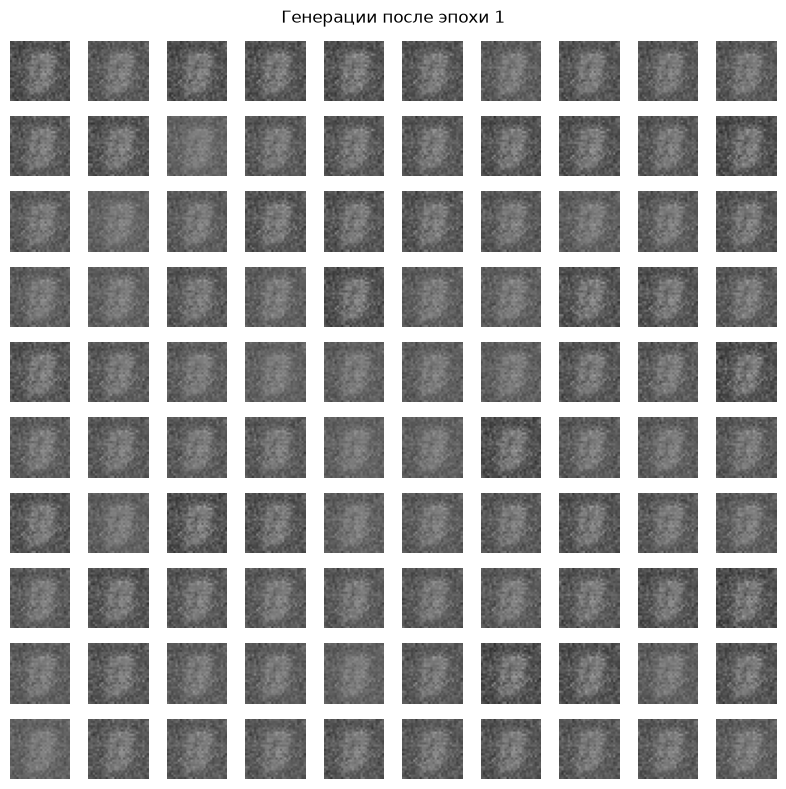

Эпоха 020: D=0.3929; G=2.9791


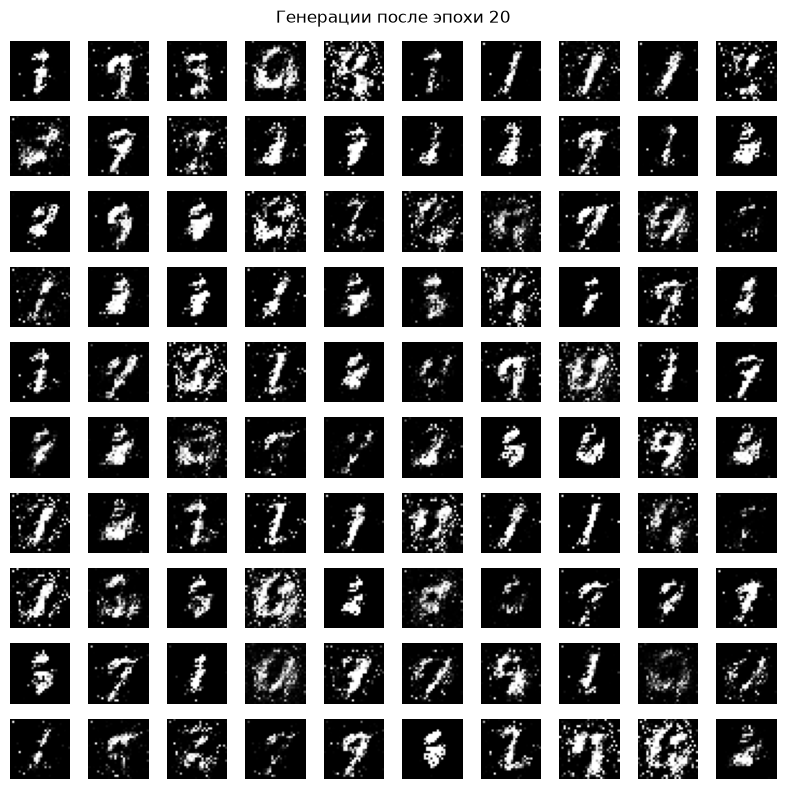

Эпоха 040: D=0.4821; G=1.9550


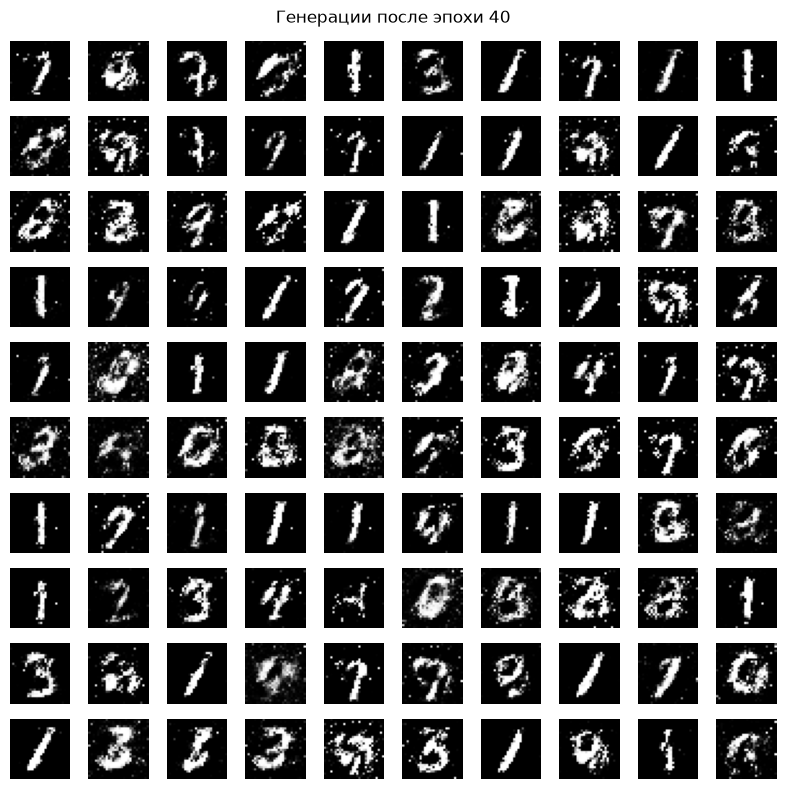

Эпоха 060: D=0.5414; G=1.5655


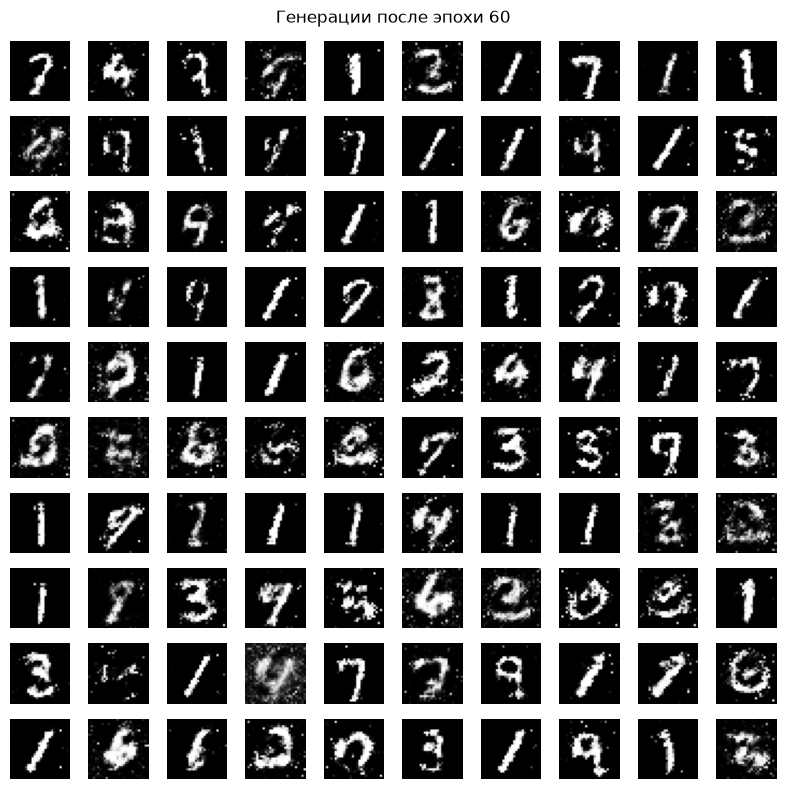

Эпоха 080: D=0.5878; G=1.3744


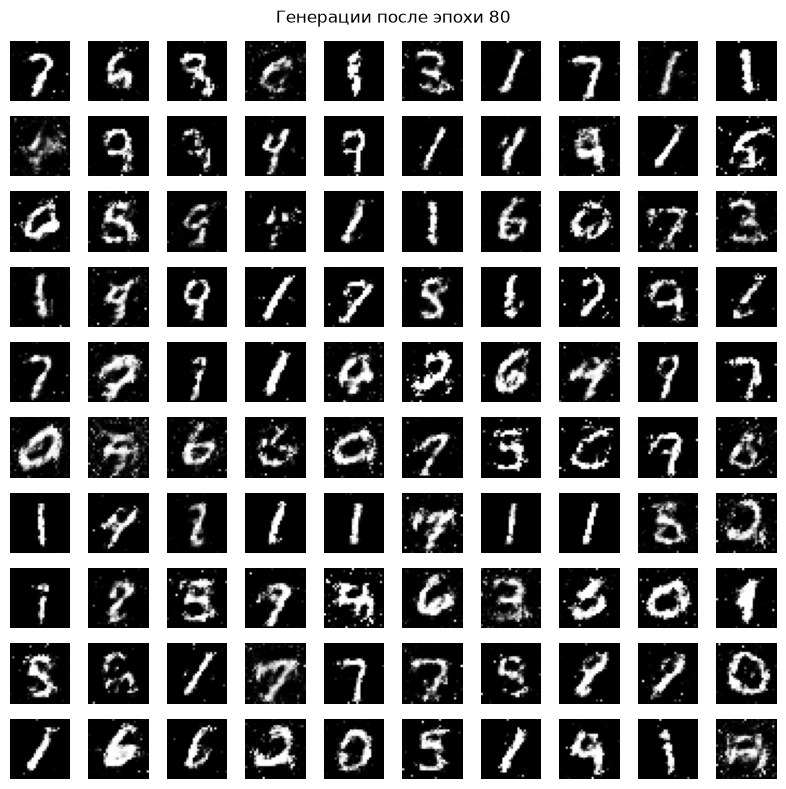

Эпоха 100: D=0.5880; G=1.3430


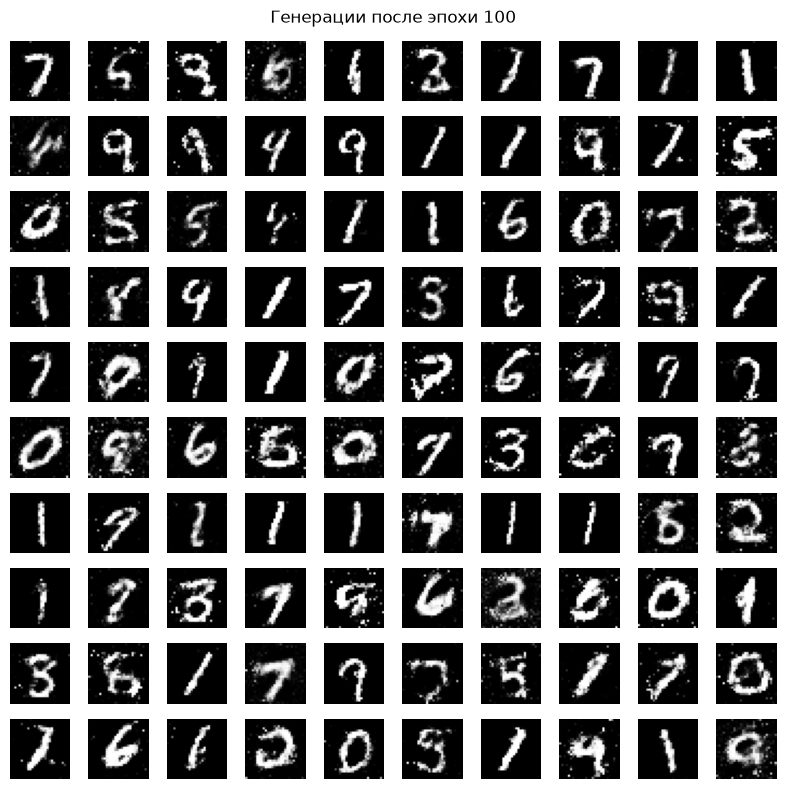

Эпоха 105: D=0.5881; G=1.3530


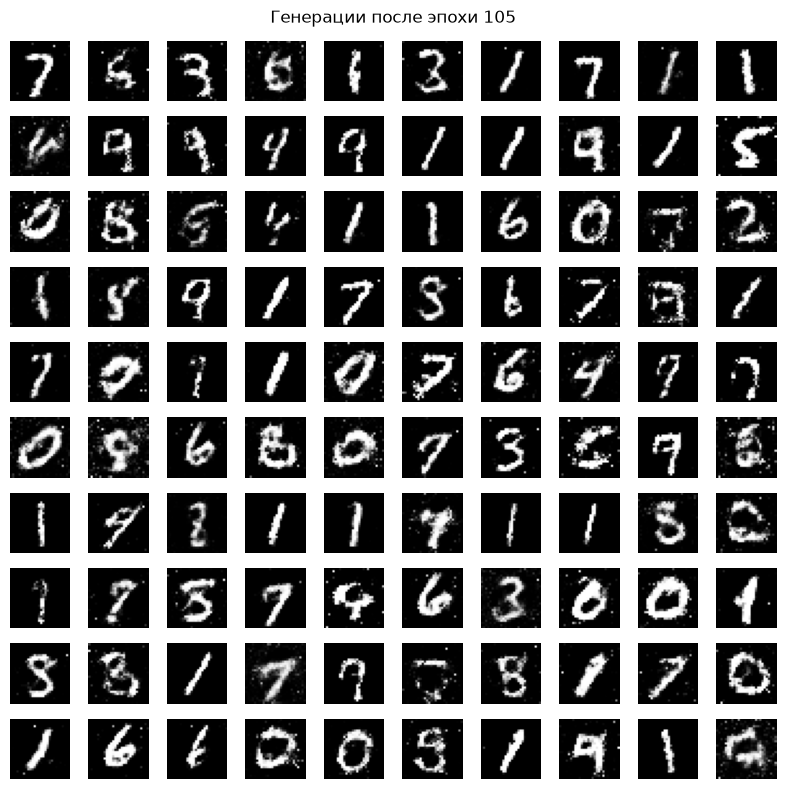

In [4]:
# D этой модели возвращает вероятности после sigmoid, а не логиты.
# BCE получает цели и вероятности одинаковой формы (B, 1).
bce = tf.keras.losses.BinaryCrossentropy(from_logits=False)
generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1,
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=LEARNING_RATE,
    beta_1=BETA_1,
)


# tf.function один раз трассирует тело в вычислительный граф; внутри
# должны применяться TensorFlow-операции, а не Python-преобразования
# тензора в float/NumPy. Вызов возвращает два скаляра Tensor.
@tf.function
def train_step(real_images: tf.Tensor):
    # Контракт: real_images имеет форму (B, 784), dtype float32 и
    # значения [-1, 1]. B может быть меньше BATCH_SIZE, поэтому он
    # берётся из фактического входа, а не из глобальной константы.
    batch_size = tf.shape(real_images)[0]

    # === Фаза 1: обновление дискриминатора D ===
    # Создаём z_D формы (B, 100). Это отдельная выборка шума: она не
    # обязана совпадать с шумом, которым далее обучается G.
    discriminator_noise = tf.random.normal((batch_size, NOISE_DIM))
    # G(z_D) имеет форму (B, 784). training=False выключает режимы,
    # зависящие от обучения. stop_gradient оставляет сами числа, но
    # обрывает ребро графа: dL_D/dθ_G не будет вычислено.
    fake_before_detach = generator(discriminator_noise, training=False)
    fake_images = tf.stop_gradient(fake_before_detach)
    with tf.GradientTape() as discriminator_tape:
        # Tape записывает только операции этой области. real_scores и
        # fake_scores имеют форму (B, 1): вероятность «реальное».
        real_scores = discriminator(real_images, training=True)
        fake_scores = discriminator(fake_images, training=True)

        # ones_like/zeros_like строят цели нужной формы на том же
        # устройстве. 0.9 — мягкая цель реальных, 0 — поддельных.
        real_loss = bce(tf.ones_like(real_scores) * REAL_LABEL, real_scores)
        fake_loss = bce(tf.ones_like(fake_scores) * FAKE_LABEL, fake_scores)
        # Обе части — скаляры, усреднённые BCE по мини-пакету; 1/2
        # не меняет минимум, но балансирует вклад двух источников.
        discriminator_loss = 0.5 * (real_loss + fake_loss)

    # По скаляру L_D tape применяет цепное правило к каждому параметру
    # D. Список gradients совпадает по порядку и форме с variables.
    discriminator_gradients = discriminator_tape.gradient(
        discriminator_loss,
        discriminator.trainable_variables,
    )
    # zip образует пары (∂L_D/∂θ_D, θ_D); Adam меняет только θ_D.
    # Отсутствие θ_G в этом вызове — вторая независимая гарантия, что
    # генератор в первой фазе не обновляется.
    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    # === Фаза 2: обновление генератора G ===
    # Новый z_G делает две задачи менее связанными с конкретной
    # случайной реализацией. Его форма также равна (B, 100).
    generator_noise = tf.random.normal((batch_size, NOISE_DIM))
    with tf.GradientTape() as generator_tape:
        # G выполняется в training=True, поскольку теперь обучаются
        # именно его параметры. generated_images имеет форму (B,784).
        generated_images = generator(generator_noise, training=True)
        # training=False — режим поведения D (например, Dropout), а
        # НЕ запрет производных. Цепочка L_G→D→G(z_G) остаётся в Tape.
        generated_scores = discriminator(generated_images, training=False)
        # Цель 1 означает «пусть D примет эти синтетические объекты за
        # реальные». Это несатурирующая функция потерь генератора.
        generator_loss = bce(
            tf.ones_like(generated_scores) * GENERATOR_TARGET,
            generated_scores,
        )

    # Запрашиваем производные только по θ_G: сигнал проходит через
    # операции D к пикселям, но параметры D не входят в список целей
    # градиента и потому второй оптимизатор их не изменяет.
    generator_gradients = generator_tape.gradient(
        generator_loss,
        generator.trainable_variables,
    )
    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )
    # Эти два скаляра нужны внешнему циклу для усреднения по эпохе.
    return discriminator_loss, generator_loss


fixed_noise = tf.random.normal((100, NOISE_DIM), seed=SEED)


def save_generated_grid(epoch: int):
    # Один fixed_noise неизменен между эпохами. Поэтому различия в
    # сетках вызваны обновлением θ_G, а не новым случайным входом.
    generated = generator(fixed_noise, training=False).numpy().reshape(-1, 28, 28)
    # Matplotlib ждёт интенсивности [0,1], а G выдаёт [-1,1].
    generated = (generated + 1.0) / 2.0
    figure, axes = plt.subplots(10, 10, figsize=(8, 8))
    for axis, image in zip(axes.flat, generated):
        axis.imshow(image, cmap='gray', vmin=0.0, vmax=1.0)
        axis.axis('off')
    figure.suptitle(f'Генерации после эпохи {epoch}')
    figure.tight_layout()
    figure.savefig(artifact_dir / f'generated_epoch_{epoch:03d}.png', dpi=150)
    plt.show()
    plt.close(figure)


# История хранит средний loss, а не loss последнего пакета: это делает
# точки графика сопоставимыми между эпохами.
history = {'discriminator_loss': [], 'generator_loss': []}
for epoch in range(1, EPOCHS + 1):
    discriminator_losses = []
    generator_losses = []
    for real_batch in dataset:
        # Из dataset приходит только x_real формы (B,784); классовых
        # меток здесь нет. train_step выполняет ровно два обновления.
        discriminator_loss, generator_loss = train_step(real_batch)
        # .numpy допустим вне tf.function: сохраняем скаляры для
        # NumPy-усреднения, но не включаем это в граф производных.
        discriminator_losses.append(float(discriminator_loss.numpy()))
        generator_losses.append(float(generator_loss.numpy()))

    epoch_discriminator_loss = float(np.mean(discriminator_losses))
    epoch_generator_loss = float(np.mean(generator_losses))
    if not (np.isfinite(epoch_discriminator_loss) and np.isfinite(epoch_generator_loss)):
        raise FloatingPointError('Одна из потерь GAN не является конечным числом.')
    history['discriminator_loss'].append(epoch_discriminator_loss)
    history['generator_loss'].append(epoch_generator_loss)

    if epoch == 1 or epoch % SAVE_EVERY == 0 or epoch == EPOCHS:
        print(
            f'Эпоха {epoch:03d}: D={epoch_discriminator_loss:.4f}; '
            f'G={epoch_generator_loss:.4f}'
        )
        save_generated_grid(epoch)

## Этап 5. Интерпретация результата

**Вход:** история средних потерь по эпохам и фиксированные 100 шумовых
векторов. **Действие:** построить обе кривые и сопоставить изображения
из одной и той же сетки в разные моменты обучения. **Важно:** потери
GAN не обязаны монотонно уменьшаться, поскольку каждая сеть меняет
задачу другой. Проверяется конечность значений, визуальное появление
контуров и разнообразие результатов, а не классификационная точность.

### Как смотреть на результат

`fixed_noise` — одни и те же 100 карточек со случайными числами во
все моменты эксперимента. Поэтому сетка после 20-й и 100-й эпох
отвечает на понятный вопрос: «как изменился рисунок для той же
карточки?». Перед показом `[-1,1]` снова превращается в `[0,1]`, что
нужно только программе рисования, а не модели.

Две линии потерь — не школьная оценка качества. Если проверяющий стал
сильнее, его ошибка может уменьшиться, а ошибка художника — возрасти;
затем ситуация меняется. Смотрите одновременно на конечность чисел,
на сетки и на разнообразие: одинаковая цифра во всех клетках является
признаком коллапса, даже если ни одна линия не выглядит тревожно.

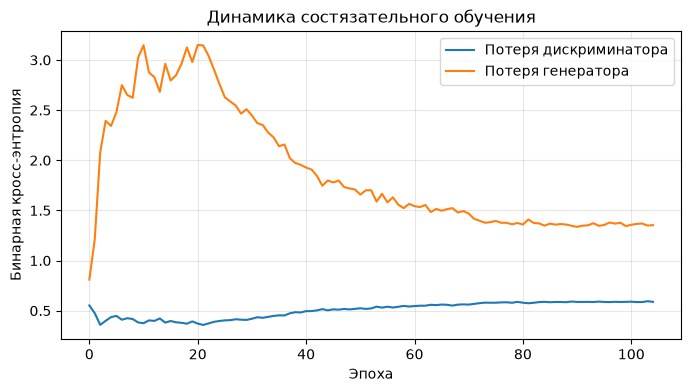

Финальная средняя оценка D для фиксированных генераций: 0.2583122253417969
Сохранённые сетки: ['generated_epoch_001.png', 'generated_epoch_020.png', 'generated_epoch_040.png', 'generated_epoch_060.png', 'generated_epoch_080.png', 'generated_epoch_100.png', 'generated_epoch_105.png']


In [5]:
assert len(history['discriminator_loss']) == EPOCHS
assert len(history['generator_loss']) == EPOCHS
assert np.isfinite(history['discriminator_loss']).all()
assert np.isfinite(history['generator_loss']).all()

plt.figure(figsize=(8, 4))
plt.plot(history['discriminator_loss'], label='Потеря дискриминатора')
plt.plot(history['generator_loss'], label='Потеря генератора')
plt.xlabel('Эпоха')
plt.ylabel('Бинарная кросс-энтропия')
plt.title('Динамика состязательного обучения')
plt.grid(alpha=0.3)
plt.legend()
plt.show()

final_images = generator(fixed_noise, training=False)
final_scores = discriminator(final_images, training=False)
assert final_images.shape == (100, IMAGE_DIM)
assert final_scores.shape == (100, 1)
assert bool(tf.reduce_all(tf.math.is_finite(final_scores)))
print('Финальная средняя оценка D для фиксированных генераций:', float(tf.reduce_mean(final_scores)))
print('Сохранённые сетки:', sorted(path.name for path in artifact_dir.glob('generated_epoch_*.png')))